In [1]:
import configparser
import os

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
os.chdir('../')

Select Dataset

In [3]:
dataset = 'TCGA' # Giannakis, Seshagiri, TCGA, all

In [4]:
data = configparser.ConfigParser(interpolation=configparser.ExtendedInterpolation())
data.read('data.ini')
data = data['DEFAULT']

In [5]:
hypoThreshold = float(data['hypoThreshold'])
hyperThreshold = float(data['hyperThreshold'])

## All samples

### Read Data

In [6]:
dataMutations = pd.read_csv(data[f'{dataset}_all___mutations'], sep='\t', comment='#', engine='python')
dataMutations

,Tumor_Sample_Barcode,Hugo_Symbol,original_Hugo_Symbol,Chromosome,Start_Position,End_Position,Strand,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele1,Tumor_Seq_Allele2,HGVSc,HGVSp_Short,Protein_position,Transcript_ID,Gene_Length,Mutation_Length,Protein_Length
0,coadread_dfci_2016_1231,A1BG,A1BG,19,58862793,58862793,+,Missense_Mutation,SNP,C,C,T,ENST00000263100.3:c.874G>A,p.G292R,292.0,ENST00000263100,8322,1,495
1,coadread_dfci_2016_1231,A1BG,A1BG,19,58862794,58862794,+,Silent,SNP,G,G,A,ENST00000263100.3:c.873C>T,p.S291=,291.0,ENST00000263100,8322,1,495
2,coadread_dfci_2016_2269,A1BG,A1BG,19,58862775,58862775,+,Missense_Mutation,SNP,C,C,T,ENST00000263100.3:c.892G>A,p.E298K,298.0,ENST00000263100,8322,1,495
3,coadread_dfci_2016_230737,A1BG,A1BG,19,58858744,58858744,+,Silent,SNP,G,G,A,ENST00000263100.3:c.1455C>T,p.S485=,485.0,ENST00000263100,8322,1,495
4,coadread_dfci_2016_2429,A1BG,A1BG,19,58862934,58862934,+,Missense_Mutation,SNP,G,G,A,ENST00000263100.3:c.733C>T,p.R245C,245.0,ENST00000263100,8322,1,495
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
591220,TCGA-WS-AB45-01,TBL1X,TBL1X,X,9661224,9661224,+,Silent,SNP,C,C,T,ENST00000217964.7:c.927C>T,p.D309=,309.0,ENST00000217964,256446,1,577
591221,TCGA-WS-AB45-01,SHROOM2,SHROOM2,X,9863424,9863424,+,Silent,SNP,G,G,A,ENST00000380913.3:c.1476G>A,p.A492=,492.0,ENST00000380913,162988,1,1616
591222,TCGA-WS-AB45-01,PCDH19,PCDH19,X,99662857,99662857,+,Missense_Mutation,SNP,C,C,T,ENST00000373034.4:c.739G>A,p.V247M,247.0,ENST00000373034,118630,1,1148
591223,TCGA-5M-AAT6-01,KRTAP1-1,KRTAP1-3,17,39190708,39197254,+,3'UTR,DEL,GGGGGGCAGGCAGGTACCCTCCACACGGCAGTCTGGGCGGCACCAC...,GGGGGGCAGGCAGGTACCCTCCACACGGCAGTCTGGGCGGCACCAC...,-,NaN,NaN,132.0,ENST00000306271,903,6547,177


In [7]:
dataClinicalSample = pd.read_csv(data[f'{dataset}_all___samples'], sep='\t', comment='#', engine='python')
dataClinicalSample

,SAMPLE_ID,PATIENT_ID,TUMOR_STAGE,TUMOR_PURITY,PRIMARY_TUMOR_GRADE,MSI_STATUS,CIMP_CATEGORY,ONCOTREE_CODE,CANCER_TYPE,CANCER_TYPE_DETAILED,...,TUMOR_CONTENT,GRADE,TISSUE_PROSPECTIVE_COLLECTION_INDICATOR,TISSUE_RETROSPECTIVE_COLLECTION_INDICATOR,TUMOR_TISSUE_SITE,ANEUPLOIDY_SCORE,SAMPLE_TYPE,MSI_SCORE_MANTIS,MSI_SENSOR_SCORE,TMB_NONSYNONYMOUS
0,coadread_dfci_2016_335135,coadread_dfci_2016_335135,I,NaN,NaN,NaN,NaN,COADREAD,Colorectal Adenocarcinoma,Colorectal Adenocarcinoma,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,coadread_dfci_2016_593,coadread_dfci_2016_593,II,NaN,Well-Moderate,NaN,CIMP-0/low,COADREAD,Colorectal Adenocarcinoma,Colorectal Adenocarcinoma,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,coadread_dfci_2016_2269,coadread_dfci_2016_2269,I,60.0,Well-Moderate,MSS,CIMP-0/low,COADREAD,Colorectal Adenocarcinoma,Colorectal Adenocarcinoma,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,coadread_dfci_2016_578,coadread_dfci_2016_578,II,NaN,Well-Moderate,MSS,CIMP-0/low,COADREAD,Colorectal Adenocarcinoma,Colorectal Adenocarcinoma,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,coadread_dfci_2016_3021,coadread_dfci_2016_3021,III,NaN,Well-Moderate,MSI-high,CIMP-high,COADREAD,Colorectal Adenocarcinoma,Colorectal Adenocarcinoma,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1282,TCGA-SS-A7HO-01,TCGA-SS-A7HO,NaN,NaN,NaN,NaN,NaN,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,...,NaN,NaN,No,Yes,Colon,18.0,Primary,0.3318,1.19,4.833333
1283,TCGA-T9-A92H-01,TCGA-T9-A92H,NaN,NaN,NaN,NaN,NaN,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,...,NaN,NaN,Yes,No,Colon,11.0,Primary,0.3170,0.40,5.333333
1284,TCGA-WS-AB45-01,TCGA-WS-AB45,NaN,NaN,NaN,NaN,NaN,MACR,Colorectal Adenocarcinoma,Mucinous Adenocarcinoma of the Colon and Rectum,...,NaN,NaN,No,Yes,Colon,7.0,Primary,0.6782,24.48,84.166667
1285,TCGA-5M-AAT5-01,TCGA-5M-AAT5,NaN,NaN,NaN,NaN,NaN,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,...,NaN,NaN,NaN,NaN,NaN,10.0,Primary,0.3131,0.35,2.633333


### Num mutations per sample

In [8]:
dataMutations

,Tumor_Sample_Barcode,Hugo_Symbol,original_Hugo_Symbol,Chromosome,Start_Position,End_Position,Strand,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele1,Tumor_Seq_Allele2,HGVSc,HGVSp_Short,Protein_position,Transcript_ID,Gene_Length,Mutation_Length,Protein_Length
0,coadread_dfci_2016_1231,A1BG,A1BG,19,58862793,58862793,+,Missense_Mutation,SNP,C,C,T,ENST00000263100.3:c.874G>A,p.G292R,292.0,ENST00000263100,8322,1,495
1,coadread_dfci_2016_1231,A1BG,A1BG,19,58862794,58862794,+,Silent,SNP,G,G,A,ENST00000263100.3:c.873C>T,p.S291=,291.0,ENST00000263100,8322,1,495
2,coadread_dfci_2016_2269,A1BG,A1BG,19,58862775,58862775,+,Missense_Mutation,SNP,C,C,T,ENST00000263100.3:c.892G>A,p.E298K,298.0,ENST00000263100,8322,1,495
3,coadread_dfci_2016_230737,A1BG,A1BG,19,58858744,58858744,+,Silent,SNP,G,G,A,ENST00000263100.3:c.1455C>T,p.S485=,485.0,ENST00000263100,8322,1,495
4,coadread_dfci_2016_2429,A1BG,A1BG,19,58862934,58862934,+,Missense_Mutation,SNP,G,G,A,ENST00000263100.3:c.733C>T,p.R245C,245.0,ENST00000263100,8322,1,495
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
591220,TCGA-WS-AB45-01,TBL1X,TBL1X,X,9661224,9661224,+,Silent,SNP,C,C,T,ENST00000217964.7:c.927C>T,p.D309=,309.0,ENST00000217964,256446,1,577
591221,TCGA-WS-AB45-01,SHROOM2,SHROOM2,X,9863424,9863424,+,Silent,SNP,G,G,A,ENST00000380913.3:c.1476G>A,p.A492=,492.0,ENST00000380913,162988,1,1616
591222,TCGA-WS-AB45-01,PCDH19,PCDH19,X,99662857,99662857,+,Missense_Mutation,SNP,C,C,T,ENST00000373034.4:c.739G>A,p.V247M,247.0,ENST00000373034,118630,1,1148
591223,TCGA-5M-AAT6-01,KRTAP1-1,KRTAP1-3,17,39190708,39197254,+,3'UTR,DEL,GGGGGGCAGGCAGGTACCCTCCACACGGCAGTCTGGGCGGCACCAC...,GGGGGGCAGGCAGGTACCCTCCACACGGCAGTCTGGGCGGCACCAC...,-,NaN,NaN,132.0,ENST00000306271,903,6547,177


In [9]:
dataMutations.groupby('Tumor_Sample_Barcode').size().sort_values(ascending=False)

Tumor_Sample_Barcode
TCGA-AG-A002-01            13820
TCGA-CA-6717-01            11582
TCGA-F5-6814-01            11277
TCGA-AA-A010-01             9339
587376                      9212
                           ...  
TCGA-AA-A00Z-01               16
TCGA-AG-3574-01               15
TCGA-AG-3605-01               14
TCGA-AH-6547-01               13
coadread_dfci_2016_2997        4
Length: 1219, dtype: int64

In [10]:
mean = dataMutations.groupby('Tumor_Sample_Barcode').size().mean()
median = dataMutations.groupby('Tumor_Sample_Barcode').size().median()
mean, median

(485.00820344544707, 166.0)

### Mutation Rate Analysis

In [11]:
# merge dataMutations with dataClinicalSample on Tumor_Sample_Barcode = SAMPLE_ID and extract PATIENT_ID and mutation length
numMutatedBases_perPatient = pd.merge(dataMutations, dataClinicalSample, left_on='Tumor_Sample_Barcode', right_on='SAMPLE_ID', how='right')[['PATIENT_ID', 'Mutation_Length']].groupby('PATIENT_ID').sum().reset_index().rename(columns={'Mutation_Length': 'Number_Mutated_Bases'})
numMutatedBases_perPatient

,PATIENT_ID,Number_Mutated_Bases
0,12912,1239.0
1,12914,2280.0
2,12915,1323.0
3,12919,787.0
4,12926,1279.0
...,...,...
1282,coadread_dfci_2016_70,76.0
1283,coadread_dfci_2016_73,271.0
1284,coadread_dfci_2016_84,649.0
1285,coadread_dfci_2016_92,1303.0


In [12]:
geneLength_perGene = dataMutations[['Hugo_Symbol', 'Gene_Length']].groupby('Hugo_Symbol').max().reset_index()
geneLength_perGene

,Hugo_Symbol,Gene_Length
0,A1BG,8322
1,A1CF,86267
2,A2M,48566
3,A2ML1,64530
4,A3GALT2,14333
...,...,...
19005,ZYG11B,100889
19006,ZYX,10032
19007,ZZEF1,138576
19008,ZZZ3,121004


In [13]:
totalGeneLength = geneLength_perGene['Gene_Length'].sum()
totalGeneLength

1286749622

In [14]:
numMutatedBases_perPatient['Mutation_Rate'] = numMutatedBases_perPatient['Number_Mutated_Bases'] / totalGeneLength
numMutatedBases_perPatient['Mutation_Rate[µ]'] = numMutatedBases_perPatient['Mutation_Rate'] * 1e6
numMutatedBases_perPatient = numMutatedBases_perPatient.sort_values(by='Mutation_Rate[µ]', ascending=False).reset_index(drop=True)
numMutatedBases_perPatient

,PATIENT_ID,Number_Mutated_Bases,Mutation_Rate,Mutation_Rate[µ]
0,TCGA-AG-A002,13857.0,0.000011,10.768995
1,TCGA-CA-6717,11610.0,0.000009,9.022734
2,TCGA-F5-6814,11290.0,0.000009,8.774046
3,TCGA-AA-A010,9373.0,0.000007,7.284245
4,32908,9212.0,0.000007,7.159124
...,...,...,...,...
1282,TCGA-AG-3728,0.0,0.000000,0.000000
1283,TCGA-AA-A00L,0.0,0.000000,0.000000
1284,TCGA-AA-A00K,0.0,0.000000,0.000000
1285,TCGA-AA-A00J,0.0,0.000000,0.000000


In [15]:
numMutatedBases_perPatient['hypo/hyper'] = numMutatedBases_perPatient.apply(lambda row: 'hyper' if row['Mutation_Rate[µ]'] > hyperThreshold else ('hypo' if row['Mutation_Rate[µ]'] < hypoThreshold else ''), axis=1)
numMutatedBases_perPatient

,PATIENT_ID,Number_Mutated_Bases,Mutation_Rate,Mutation_Rate[µ],hypo/hyper
0,TCGA-AG-A002,13857.0,0.000011,10.768995,hyper
1,TCGA-CA-6717,11610.0,0.000009,9.022734,hyper
2,TCGA-F5-6814,11290.0,0.000009,8.774046,hyper
3,TCGA-AA-A010,9373.0,0.000007,7.284245,hyper
4,32908,9212.0,0.000007,7.159124,hyper
...,...,...,...,...,...
1282,TCGA-AG-3728,0.0,0.000000,0.000000,hypo
1283,TCGA-AA-A00L,0.0,0.000000,0.000000,hypo
1284,TCGA-AA-A00K,0.0,0.000000,0.000000,hypo
1285,TCGA-AA-A00J,0.0,0.000000,0.000000,hypo


In [16]:
numHyper = numMutatedBases_perPatient[numMutatedBases_perPatient['hypo/hyper'] == 'hyper'].shape[0]
numHypo = numMutatedBases_perPatient[numMutatedBases_perPatient['hypo/hyper'] == 'hypo'].shape[0]
numPatients = numMutatedBases_perPatient.shape[0]
numHyper, numHypo

(43, 120)

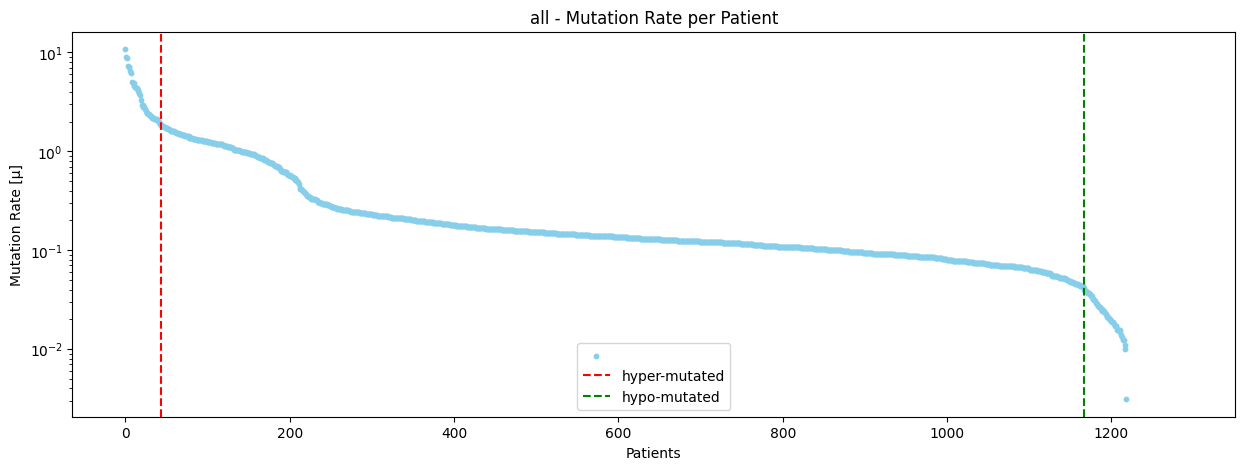

In [17]:
# plot mutation rate per patient
plt.figure(figsize=(15, 5))
plt.scatter(numMutatedBases_perPatient.index, numMutatedBases_perPatient['Mutation_Rate[µ]'], color='skyblue', s=10)
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.title(dataset + ' - Mutation Rate per Patient')
plt.axvline(x=numHyper, color='r', linestyle='--')
plt.axvline(x=numPatients-numHypo, color='g', linestyle='--')
plt.legend([None,'hyper-mutated', 'hypo-mutated'])
plt.savefig(data[f'plots___{dataset}'] + dataset + '_mutationRatePerPatient.pngthresholds')
plt.show()

In [26]:
numMutatedBases_perPatient.to_csv(data[f'{dataset}_all'] + f'{dataset}_all_mutationRates.csv', sep='\t', index=False)

In [27]:
dataMutations_noHypoHyper = dataMutations[dataMutations.merge(dataClinicalSample, left_on='Tumor_Sample_Barcode', right_on='SAMPLE_ID')['PATIENT_ID'].isin(numMutatedBases_perPatient[numMutatedBases_perPatient['hypo/hyper'] == '']['PATIENT_ID'])]
dataMutations_noHypoHyper

,Tumor_Sample_Barcode,Hugo_Symbol,original_Hugo_Symbol,Chromosome,Start_Position,End_Position,Strand,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele1,Tumor_Seq_Allele2,HGVSc,HGVSp_Short,Protein_position,Transcript_ID,Gene_Length,Mutation_Length,Protein_Length
0,coadread_dfci_2016_1231,A1BG,A1BG,19,58862793,58862793,+,Missense_Mutation,SNP,C,C,T,ENST00000263100.3:c.874G>A,p.G292R,292.0,ENST00000263100,8322,1,495
1,coadread_dfci_2016_1231,A1BG,A1BG,19,58862794,58862794,+,Silent,SNP,G,G,A,ENST00000263100.3:c.873C>T,p.S291=,291.0,ENST00000263100,8322,1,495
3,coadread_dfci_2016_230737,A1BG,A1BG,19,58858744,58858744,+,Silent,SNP,G,G,A,ENST00000263100.3:c.1455C>T,p.S485=,485.0,ENST00000263100,8322,1,495
4,coadread_dfci_2016_2429,A1BG,A1BG,19,58862934,58862934,+,Missense_Mutation,SNP,G,G,A,ENST00000263100.3:c.733C>T,p.R245C,245.0,ENST00000263100,8322,1,495
5,coadread_dfci_2016_2624,A1BG,A1BG,19,58858848,58858848,+,Missense_Mutation,SNP,C,C,T,ENST00000263100.3:c.1351G>A,p.A451T,451.0,ENST00000263100,8322,1,495
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
587853,TCGA-T9-A92H-01,GPR112,GPR112,X,135428691,135428691,+,Silent,SNP,T,T,G,ENST00000370652.1:c.2826T>G,p.T942=,942.0,ENST00000370652,136094,1,3080
587854,TCGA-T9-A92H-01,DCAF8L2,DCAF8L2,X,27766401,27766401,+,Silent,SNP,T,T,C,ENST00000451261.2:c.1389T>C,p.F463=,463.0,ENST00000451261,158410,1,631
587855,TCGA-T9-A92H-01,MAGEB1,MAGEB1,X,30269452,30269452,+,Missense_Mutation,SNP,C,C,G,ENST00000378981.3:c.842C>G,p.T281S,281.0,ENST00000378981,8309,1,347
587856,TCGA-T9-A92H-01,DMD,DMD,X,32381009,32381009,+,Missense_Mutation,SNP,A,A,C,ENST00000357033.4:c.5221T>G,p.L1741V,1741.0,ENST00000357033,2241765,1,3685


In [28]:
dataMutations_noHypoHyper.to_csv(data[f'{dataset}_noHypoHyper___mutations'], sep='\t', index=False)

In [29]:
dataClinicalSample_noHypoHyper = dataClinicalSample[dataClinicalSample['PATIENT_ID'].isin(numMutatedBases_perPatient[numMutatedBases_perPatient['hypo/hyper'] == '']['PATIENT_ID'])]
dataClinicalSample_noHypoHyper

,SAMPLE_ID,PATIENT_ID,TUMOR_STAGE,TUMOR_PURITY,PRIMARY_TUMOR_GRADE,MSI_STATUS,CIMP_CATEGORY,ONCOTREE_CODE,CANCER_TYPE,CANCER_TYPE_DETAILED,...,TUMOR_CONTENT,GRADE,TISSUE_PROSPECTIVE_COLLECTION_INDICATOR,TISSUE_RETROSPECTIVE_COLLECTION_INDICATOR,TUMOR_TISSUE_SITE,ANEUPLOIDY_SCORE,SAMPLE_TYPE,MSI_SCORE_MANTIS,MSI_SENSOR_SCORE,TMB_NONSYNONYMOUS
6,coadread_dfci_2016_207430,coadread_dfci_2016_207430,II,NaN,NaN,NaN,NaN,COADREAD,Colorectal Adenocarcinoma,Colorectal Adenocarcinoma,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,coadread_dfci_2016_1241,coadread_dfci_2016_1241,II,60.0,Well-Moderate,MSI-high,CIMP-high,COADREAD,Colorectal Adenocarcinoma,Colorectal Adenocarcinoma,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,coadread_dfci_2016_3701,coadread_dfci_2016_3701,II,66.0,Poor,MSI-high,CIMP-0/low,COADREAD,Colorectal Adenocarcinoma,Colorectal Adenocarcinoma,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,coadread_dfci_2016_3640,coadread_dfci_2016_3640,II,55.0,Poor,MSI-high,CIMP-high,COADREAD,Colorectal Adenocarcinoma,Colorectal Adenocarcinoma,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12,coadread_dfci_2016_1222,coadread_dfci_2016_1222,II,50.0,Well-Moderate,MSI-high,CIMP-high,COADREAD,Colorectal Adenocarcinoma,Colorectal Adenocarcinoma,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1281,TCGA-RU-A8FL-01,TCGA-RU-A8FL,NaN,NaN,NaN,NaN,NaN,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,...,NaN,NaN,No,Yes,Colon,26.0,Primary,0.3417,0.47,4.200000
1282,TCGA-SS-A7HO-01,TCGA-SS-A7HO,NaN,NaN,NaN,NaN,NaN,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,...,NaN,NaN,No,Yes,Colon,18.0,Primary,0.3318,1.19,4.833333
1283,TCGA-T9-A92H-01,TCGA-T9-A92H,NaN,NaN,NaN,NaN,NaN,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,...,NaN,NaN,Yes,No,Colon,11.0,Primary,0.3170,0.40,5.333333
1285,TCGA-5M-AAT5-01,TCGA-5M-AAT5,NaN,NaN,NaN,NaN,NaN,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,...,NaN,NaN,NaN,NaN,NaN,10.0,Primary,0.3131,0.35,2.633333


In [30]:
dataClinicalSample_noHypoHyper.to_csv(data[f'{dataset}_noHypoHyper___samples'], sep='\t', index=False)

### Mutation Frequency Analysis

In [36]:
patientsGenes = pd.merge(dataMutations, dataClinicalSample, left_on='Tumor_Sample_Barcode', right_on='SAMPLE_ID')[['PATIENT_ID', 'Hugo_Symbol']].drop_duplicates().reset_index(drop=True)
patientsGenes

,PATIENT_ID,Hugo_Symbol
0,coadread_dfci_2016_1231,A1BG
1,coadread_dfci_2016_2269,A1BG
2,coadread_dfci_2016_230737,A1BG
3,coadread_dfci_2016_2429,A1BG
4,coadread_dfci_2016_2624,A1BG
...,...,...
507975,TCGA-WS-AB45,TBL1X
507976,TCGA-WS-AB45,SHROOM2
507977,TCGA-WS-AB45,PCDH19
507978,TCGA-5M-AAT6,KRTAP1-1


In [37]:
numPatients_perGene = patientsGenes.groupby('Hugo_Symbol').count().reset_index().rename(columns={'PATIENT_ID': 'Number_Patients'})
numPatients_perGene

,Hugo_Symbol,Number_Patients
0,A1BG,31
1,A1CF,27
2,A2M,74
3,A2ML1,95
4,A3GALT2,10
...,...,...
19005,ZYG11B,32
19006,ZYX,25
19007,ZZEF1,92
19008,ZZZ3,37


In [38]:
numPatients = dataClinicalSample['PATIENT_ID'].nunique()
numPatients

1287

In [39]:
numPatients_perGene['Mutation_Frequency[%]'] = numPatients_perGene['Number_Patients'] / numPatients * 100
numPatients_perGene = numPatients_perGene.sort_values(by='Mutation_Frequency[%]', ascending=False).reset_index(drop=True)
numPatients_perGene

,Hugo_Symbol,Number_Patients,Mutation_Frequency[%]
0,APC,775,60.217560
1,TP53,651,50.582751
2,TTN,647,50.271950
3,KRAS,428,33.255633
4,SYNE1,376,29.215229
...,...,...,...
19005,UQCR11,1,0.077700
19006,C1orf147,1,0.077700
19007,EXOSC6,1,0.077700
19008,SLC15A5,1,0.077700


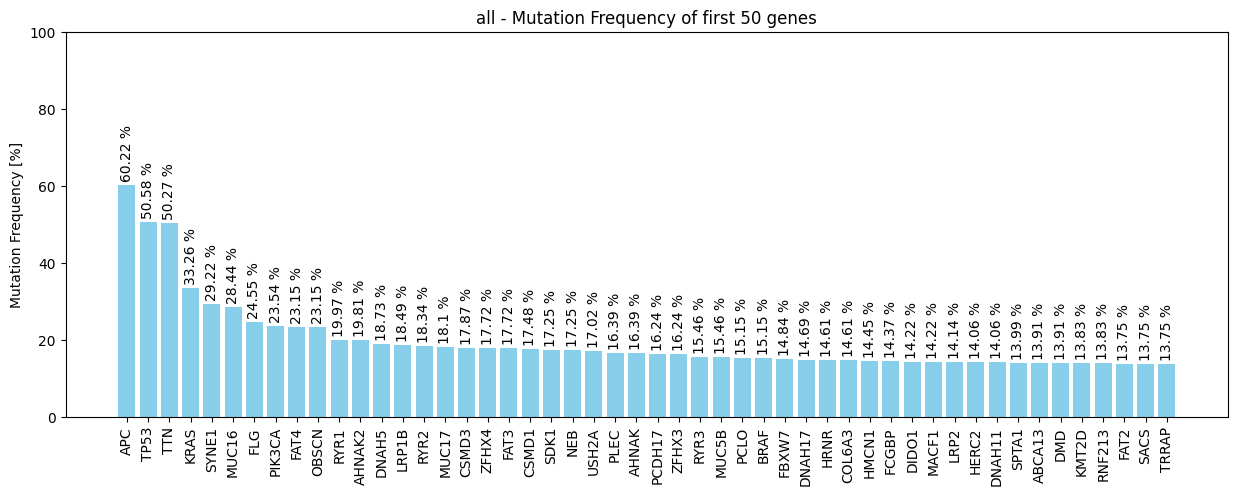

In [40]:
# plot mutation frequency of first 50 genes
plt.figure(figsize=(15, 5))
plt.bar(numPatients_perGene['Hugo_Symbol'][:50], numPatients_perGene['Mutation_Frequency[%]'][:50], color='skyblue')
plt.xticks(rotation=90)
plt.ylabel('Mutation Frequency [%]')
plt.title(dataset + ' - Mutation Frequency of first 50 genes')
# add value over each bar rotated 90 degree
for i, v in enumerate(numPatients_perGene['Mutation_Frequency[%]'][:50]):
    plt.text(i, v+1, str(round(v, 2))+ ' %', ha='center', va='bottom', rotation=90)
plt.ylim(0, 100)
plt.savefig(data[f'plots___{dataset}'] + dataset +  '_mutationFrequency_first50genes.png')
plt.show()

### _CleanMemory

In [67]:
del dataMutations, dataClinicalSample, numMutatedBases_perPatient, geneLength_perGene, patientsGenes, numPatients_perGene

## RAS-mutated samples

### Read Data

In [25]:
dataMutations_RAS = pd.read_csv(data[f'{dataset}_RAS___mutations'], sep='\t', comment='#', engine='python')
dataMutations_RAS

,Tumor_Sample_Barcode,Hugo_Symbol,original_Hugo_Symbol,Chromosome,Start_Position,End_Position,Strand,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele1,Tumor_Seq_Allele2,HGVSc,HGVSp_Short,Protein_position,Transcript_ID,Gene_Length,Mutation_Length,Protein_Length
0,TCGA-AF-4110-01,INA,INA,10,105046867,105046867,+,Missense_Mutation,SNP,G,G,T,ENST00000369849.4:c.1141G>T,p.D381Y,381.0,ENST00000369849,13189,1,499
1,TCGA-AF-4110-01,TCF7L2,TCF7L2,10,114901049,114901050,+,Frame_Shift_Ins,INS,-,-,A,ENST00000355995.4:c.660dupA,p.P221Tfs*107,220.0,ENST00000355995,217429,2,619
2,TCGA-AF-4110-01,HABP2,HABP2,10,115338404,115338404,+,Missense_Mutation,SNP,T,T,C,ENST00000351270.3:c.587T>C,p.V196A,196.0,ENST00000351270,38766,1,560
3,TCGA-AF-4110-01,NRAP,NRAP,10,115356930,115356930,+,Missense_Mutation,SNP,T,T,C,ENST00000359988.3:c.4346A>G,p.K1449R,1449.0,ENST00000359988,75412,1,1730
4,TCGA-AF-4110-01,PNLIPRP2,PNLIPRP2,10,118383592,118383592,+,Silent,SNP,A,A,G,ENST00000537242.1:c.186A>G,p.E62=,62.0,ENST00000537242,24190,1,468
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115441,TCGA-SS-A7HO-01,BCOR,BCOR,X,39923064,39923065,+,Frame_Shift_Ins,INS,-,-,T,ENST00000378444.4:c.3643dup,p.R1215Kfs*30,1215.0,ENST00000378444,127515,2,1755
115442,TCGA-SS-A7HO-01,WDR13,WDR13,X,48457983,48457983,+,Missense_Mutation,SNP,G,G,A,ENST00000218056.5:c.401G>A,p.G134D,134.0,ENST00000218056,15152,1,485
115443,TCGA-SS-A7HO-01,HDAC6,HDAC6,X,48674640,48674640,+,Missense_Mutation,SNP,G,G,T,ENST00000334136.5:c.1586G>T,p.R529L,529.0,ENST00000334136,23609,1,1215
115444,TCGA-SS-A7HO-01,PCDH11X,PCDH11X,X,91132348,91132348,+,Missense_Mutation,SNP,T,T,C,ENST00000373094.1:c.1109T>C,p.L370P,370.0,ENST00000373094,843970,1,1347


In [26]:
dataClinicalSample_RAS = pd.read_csv(data[f'{dataset}_RAS___samples'], sep='\t', comment='#', engine='python')
dataClinicalSample_RAS

,PATIENT_ID,SAMPLE_ID,ONCOTREE_CODE,CANCER_TYPE,CANCER_TYPE_DETAILED,TUMOR_TYPE,GRADE,TISSUE_PROSPECTIVE_COLLECTION_INDICATOR,TISSUE_RETROSPECTIVE_COLLECTION_INDICATOR,TISSUE_SOURCE_SITE,TUMOR_TISSUE_SITE,ANEUPLOIDY_SCORE,SAMPLE_TYPE,MSI_SCORE_MANTIS,MSI_SENSOR_SCORE,SOMATIC_STATUS,TMB_NONSYNONYMOUS
0,TCGA-AF-4110,TCGA-AF-4110-01,READ,Colorectal Adenocarcinoma,Rectal Adenocarcinoma,Rectum Adenocarcinoma,NaN,Yes,No,AF,NaN,23.0,Primary,0.3522,0.06,Matched,2.866667
1,TCGA-AF-5654,TCGA-AF-5654-01,READ,Colorectal Adenocarcinoma,Rectal Adenocarcinoma,Rectal Adenocarcinoma,NaN,Yes,No,AF,Rectum,8.0,Primary,0.3231,0.19,Matched,8.033333
2,TCGA-AF-6136,TCGA-AF-6136-01,READ,Colorectal Adenocarcinoma,Rectal Adenocarcinoma,Rectal Adenocarcinoma,NaN,Yes,No,AF,Rectum,27.0,Primary,0.3329,0.16,Matched,3.633333
3,TCGA-AF-6655,TCGA-AF-6655-01,READ,Colorectal Adenocarcinoma,Rectal Adenocarcinoma,Rectal Adenocarcinoma,NaN,Yes,No,AF,Rectum,19.0,Primary,0.3465,0.16,Matched,2.133333
4,TCGA-AF-6672,TCGA-AF-6672-01,READ,Colorectal Adenocarcinoma,Rectal Adenocarcinoma,Rectal Adenocarcinoma,NaN,Yes,No,AF,Rectum,21.0,Primary,0.3345,0.02,Matched,2.533333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249,TCGA-QG-A5YV,TCGA-QG-A5YV-01,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,Colon Adenocarcinoma,NaN,No,Yes,QG,Colon,18.0,Primary,0.2586,0.00,Matched,5.400000
250,TCGA-QG-A5Z2,TCGA-QG-A5Z2-01,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,Colon Adenocarcinoma,NaN,No,Yes,QG,Colon,0.0,Primary,0.8600,19.29,Matched,34.200000
251,TCGA-QL-A97D,TCGA-QL-A97D-01,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,Colon Adenocarcinoma,NaN,No,Yes,QL,Colon,21.0,Primary,0.3204,0.56,Matched,7.066667
252,TCGA-SS-A7HO,TCGA-SS-A7HO-01,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,Colon Adenocarcinoma,NaN,No,Yes,SS,Colon,18.0,Primary,0.3318,1.19,Matched,4.833333


### Mutation Rate Analysis

In [27]:
# merge dataMutations with dataClinicalSample on Tumor_Sample_Barcode = SAMPLE_ID and extract PATIENT_ID and mutation length
numMutatedBases_perPatient_RAS = pd.merge(dataMutations_RAS, dataClinicalSample_RAS, left_on='Tumor_Sample_Barcode', right_on='SAMPLE_ID', how='right')[['PATIENT_ID', 'Mutation_Length']].groupby('PATIENT_ID').sum().reset_index().rename(columns={'Mutation_Length': 'Number_Mutated_Bases'})
numMutatedBases_perPatient_RAS

,PATIENT_ID,Number_Mutated_Bases
0,TCGA-3L-AA1B,175
1,TCGA-4N-A93T,157
2,TCGA-4T-AA8H,160
3,TCGA-5M-AAT4,233
4,TCGA-5M-AAT5,112
...,...,...
249,TCGA-NH-A8F8,139
250,TCGA-QG-A5YV,213
251,TCGA-QG-A5Z2,1410
252,TCGA-QL-A97D,297


In [28]:
numMutatedBases_perPatient_RAS['Mutation_Rate'] = numMutatedBases_perPatient_RAS['Number_Mutated_Bases'] / totalGeneLength
numMutatedBases_perPatient_RAS['Mutation_Rate[µ]'] = numMutatedBases_perPatient_RAS['Mutation_Rate'] * 1e6
numMutatedBases_perPatient_RAS = numMutatedBases_perPatient_RAS.sort_values(by='Mutation_Rate[µ]', ascending=False).reset_index(drop=True)
numMutatedBases_perPatient_RAS

,PATIENT_ID,Number_Mutated_Bases,Mutation_Rate,Mutation_Rate[µ]
0,TCGA-F5-6814,11290,8.825526e-06,8.825526
1,TCGA-5M-AAT6,9071,7.090908e-06,7.090908
2,TCGA-AZ-4315,8024,6.272455e-06,6.272455
3,TCGA-AA-A00N,6264,4.896643e-06,4.896643
4,TCGA-AA-3977,4259,3.329310e-06,3.329310
...,...,...,...,...
249,TCGA-AA-A02F,78,6.097352e-08,0.060974
250,TCGA-A6-A567,76,5.941010e-08,0.059410
251,TCGA-DC-6155,68,5.315640e-08,0.053156
252,TCGA-CA-5255,67,5.237469e-08,0.052375


In [29]:
numMutatedBases_perPatient_RAS['hypo/hyper'] = numMutatedBases_perPatient_RAS.apply(lambda row: 'hyper' if row['Mutation_Rate[µ]'] > hyperThreshold else ('hypo' if row['Mutation_Rate[µ]'] < hypoThreshold else ''), axis=1)
numMutatedBases_perPatient_RAS

,PATIENT_ID,Number_Mutated_Bases,Mutation_Rate,Mutation_Rate[µ],hypo/hyper
0,TCGA-F5-6814,11290,8.825526e-06,8.825526,hyper
1,TCGA-5M-AAT6,9071,7.090908e-06,7.090908,hyper
2,TCGA-AZ-4315,8024,6.272455e-06,6.272455,hyper
3,TCGA-AA-A00N,6264,4.896643e-06,4.896643,hyper
4,TCGA-AA-3977,4259,3.329310e-06,3.329310,hyper
...,...,...,...,...,...
249,TCGA-AA-A02F,78,6.097352e-08,0.060974,
250,TCGA-A6-A567,76,5.941010e-08,0.059410,
251,TCGA-DC-6155,68,5.315640e-08,0.053156,
252,TCGA-CA-5255,67,5.237469e-08,0.052375,


In [30]:
numHyper = numMutatedBases_perPatient_RAS[numMutatedBases_perPatient_RAS['hypo/hyper'] == 'hyper'].shape[0]
numHypo = numMutatedBases_perPatient_RAS[numMutatedBases_perPatient_RAS['hypo/hyper'] == 'hypo'].shape[0]
numPatients = numMutatedBases_perPatient_RAS.shape[0]
numHyper, numHypo

(14, 0)

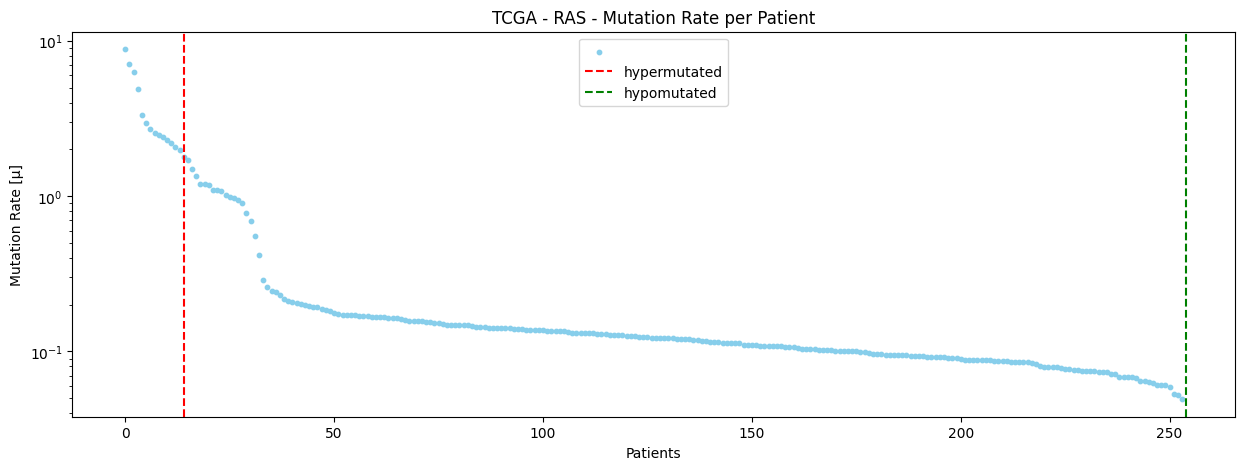

In [31]:
# plot mutation rate per patient
plt.figure(figsize=(15, 5))
plt.scatter(numMutatedBases_perPatient_RAS.index, numMutatedBases_perPatient_RAS['Mutation_Rate[µ]'], color='skyblue', s=10)
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.axvline(x=numHyper, color='r', linestyle='--')
plt.axvline(x=numPatients-numHypo, color='g', linestyle='--')
plt.legend([None,'hypermutated', 'hypomutated'])
plt.title(dataset + ' - RAS - Mutation Rate per Patient')
# plt.xticks([])
plt.savefig(data[f'plots___{dataset}'] + dataset +  '_mutationRatePerPatient_RAS.png')
plt.show()

In [32]:
dataMutations_noHypoHyper_RAS = dataMutations_RAS[dataMutations_RAS.merge(dataClinicalSample_RAS, left_on='Tumor_Sample_Barcode', right_on='SAMPLE_ID')['PATIENT_ID'].isin(numMutatedBases_perPatient_RAS[numMutatedBases_perPatient_RAS['hypo/hyper'] == '']['PATIENT_ID'])]
dataMutations_noHypoHyper_RAS

,Tumor_Sample_Barcode,Hugo_Symbol,original_Hugo_Symbol,Chromosome,Start_Position,End_Position,Strand,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele1,Tumor_Seq_Allele2,HGVSc,HGVSp_Short,Protein_position,Transcript_ID,Gene_Length,Mutation_Length,Protein_Length
0,TCGA-AF-4110-01,INA,INA,10,105046867,105046867,+,Missense_Mutation,SNP,G,G,T,ENST00000369849.4:c.1141G>T,p.D381Y,381.0,ENST00000369849,13189,1,499
1,TCGA-AF-4110-01,TCF7L2,TCF7L2,10,114901049,114901050,+,Frame_Shift_Ins,INS,-,-,A,ENST00000355995.4:c.660dupA,p.P221Tfs*107,220.0,ENST00000355995,217429,2,619
2,TCGA-AF-4110-01,HABP2,HABP2,10,115338404,115338404,+,Missense_Mutation,SNP,T,T,C,ENST00000351270.3:c.587T>C,p.V196A,196.0,ENST00000351270,38766,1,560
3,TCGA-AF-4110-01,NRAP,NRAP,10,115356930,115356930,+,Missense_Mutation,SNP,T,T,C,ENST00000359988.3:c.4346A>G,p.K1449R,1449.0,ENST00000359988,75412,1,1730
4,TCGA-AF-4110-01,PNLIPRP2,PNLIPRP2,10,118383592,118383592,+,Silent,SNP,A,A,G,ENST00000537242.1:c.186A>G,p.E62=,62.0,ENST00000537242,24190,1,468
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115440,TCGA-SS-A7HO-01,MID1IP1,MID1IP1,X,38664322,38664322,+,Silent,SNP,G,G,T,ENST00000336949.6:c.123G>T,p.V41=,41.0,ENST00000336949,5106,1,183
115441,TCGA-SS-A7HO-01,BCOR,BCOR,X,39923064,39923065,+,Frame_Shift_Ins,INS,-,-,T,ENST00000378444.4:c.3643dup,p.R1215Kfs*30,1215.0,ENST00000378444,127515,2,1755
115442,TCGA-SS-A7HO-01,WDR13,WDR13,X,48457983,48457983,+,Missense_Mutation,SNP,G,G,A,ENST00000218056.5:c.401G>A,p.G134D,134.0,ENST00000218056,15152,1,485
115443,TCGA-SS-A7HO-01,HDAC6,HDAC6,X,48674640,48674640,+,Missense_Mutation,SNP,G,G,T,ENST00000334136.5:c.1586G>T,p.R529L,529.0,ENST00000334136,23609,1,1215


In [33]:
dataMutations_noHypoHyper_RAS.to_csv(data[f'{dataset}_noHypoHyper_RAS___mutations'], sep='\t', index=False)

In [34]:
dataClinicalSample_noHypoHyper_RAS = dataClinicalSample_RAS[dataClinicalSample_RAS['PATIENT_ID'].isin(numMutatedBases_perPatient_RAS[numMutatedBases_perPatient_RAS['hypo/hyper'] == '']['PATIENT_ID'])]
dataClinicalSample_noHypoHyper_RAS

,PATIENT_ID,SAMPLE_ID,ONCOTREE_CODE,CANCER_TYPE,CANCER_TYPE_DETAILED,TUMOR_TYPE,GRADE,TISSUE_PROSPECTIVE_COLLECTION_INDICATOR,TISSUE_RETROSPECTIVE_COLLECTION_INDICATOR,TISSUE_SOURCE_SITE,TUMOR_TISSUE_SITE,ANEUPLOIDY_SCORE,SAMPLE_TYPE,MSI_SCORE_MANTIS,MSI_SENSOR_SCORE,SOMATIC_STATUS,TMB_NONSYNONYMOUS
0,TCGA-AF-4110,TCGA-AF-4110-01,READ,Colorectal Adenocarcinoma,Rectal Adenocarcinoma,Rectum Adenocarcinoma,NaN,Yes,No,AF,NaN,23.0,Primary,0.3522,0.06,Matched,2.866667
1,TCGA-AF-5654,TCGA-AF-5654-01,READ,Colorectal Adenocarcinoma,Rectal Adenocarcinoma,Rectal Adenocarcinoma,NaN,Yes,No,AF,Rectum,8.0,Primary,0.3231,0.19,Matched,8.033333
2,TCGA-AF-6136,TCGA-AF-6136-01,READ,Colorectal Adenocarcinoma,Rectal Adenocarcinoma,Rectal Adenocarcinoma,NaN,Yes,No,AF,Rectum,27.0,Primary,0.3329,0.16,Matched,3.633333
3,TCGA-AF-6655,TCGA-AF-6655-01,READ,Colorectal Adenocarcinoma,Rectal Adenocarcinoma,Rectal Adenocarcinoma,NaN,Yes,No,AF,Rectum,19.0,Primary,0.3465,0.16,Matched,2.133333
4,TCGA-AF-6672,TCGA-AF-6672-01,READ,Colorectal Adenocarcinoma,Rectal Adenocarcinoma,Rectal Adenocarcinoma,NaN,Yes,No,AF,Rectum,21.0,Primary,0.3345,0.02,Matched,2.533333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249,TCGA-QG-A5YV,TCGA-QG-A5YV-01,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,Colon Adenocarcinoma,NaN,No,Yes,QG,Colon,18.0,Primary,0.2586,0.00,Matched,5.400000
250,TCGA-QG-A5Z2,TCGA-QG-A5Z2-01,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,Colon Adenocarcinoma,NaN,No,Yes,QG,Colon,0.0,Primary,0.8600,19.29,Matched,34.200000
251,TCGA-QL-A97D,TCGA-QL-A97D-01,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,Colon Adenocarcinoma,NaN,No,Yes,QL,Colon,21.0,Primary,0.3204,0.56,Matched,7.066667
252,TCGA-SS-A7HO,TCGA-SS-A7HO-01,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,Colon Adenocarcinoma,NaN,No,Yes,SS,Colon,18.0,Primary,0.3318,1.19,Matched,4.833333


In [35]:
dataClinicalSample_noHypoHyper_RAS.to_csv(data[f'{dataset}_noHypoHyper_RAS___samples'], sep='\t', index=False)

### Mutation Frequency Analysis

In [36]:
patientsGenes_RAS = pd.merge(dataMutations_RAS, dataClinicalSample_RAS, left_on='Tumor_Sample_Barcode', right_on='SAMPLE_ID')[['PATIENT_ID', 'Hugo_Symbol']].drop_duplicates().reset_index(drop=True)
patientsGenes_RAS

,PATIENT_ID,Hugo_Symbol
0,TCGA-AF-4110,INA
1,TCGA-AF-4110,TCF7L2
2,TCGA-AF-4110,HABP2
3,TCGA-AF-4110,NRAP
4,TCGA-AF-4110,PNLIPRP2
...,...,...
98286,TCGA-SS-A7HO,BCOR
98287,TCGA-SS-A7HO,WDR13
98288,TCGA-SS-A7HO,HDAC6
98289,TCGA-SS-A7HO,PCDH11X


In [37]:
numPatients_perGene_RAS = patientsGenes_RAS.groupby('Hugo_Symbol').count().reset_index().rename(columns={'PATIENT_ID': 'Number_Patients'})
numPatients_perGene_RAS

,Hugo_Symbol,Number_Patients
0,A1BG,4
1,A1CF,5
2,A2M,12
3,A2ML1,22
4,A4GALT,6
...,...,...
17335,ZYG11A,9
17336,ZYG11B,6
17337,ZYX,4
17338,ZZEF1,12


In [38]:
numPatients_RAS = dataClinicalSample_RAS['PATIENT_ID'].nunique()
numPatients_RAS

254

In [39]:
numPatients_perGene_RAS['Mutation_Frequency[%]'] = numPatients_perGene_RAS['Number_Patients'] / numPatients_RAS * 100
numPatients_perGene_RAS = numPatients_perGene_RAS.sort_values(by='Mutation_Frequency[%]', ascending=False).reset_index(drop=True)
numPatients_perGene_RAS

,Hugo_Symbol,Number_Patients,Mutation_Frequency[%]
0,KRAS,218,85.826772
1,APC,211,83.070866
2,TTN,145,57.086614
3,TP53,142,55.905512
4,PIK3CA,92,36.220472
...,...,...,...
17335,GPR119,1,0.393701
17336,PRSS27,1,0.393701
17337,CD300LD,1,0.393701
17338,PRSS22,1,0.393701


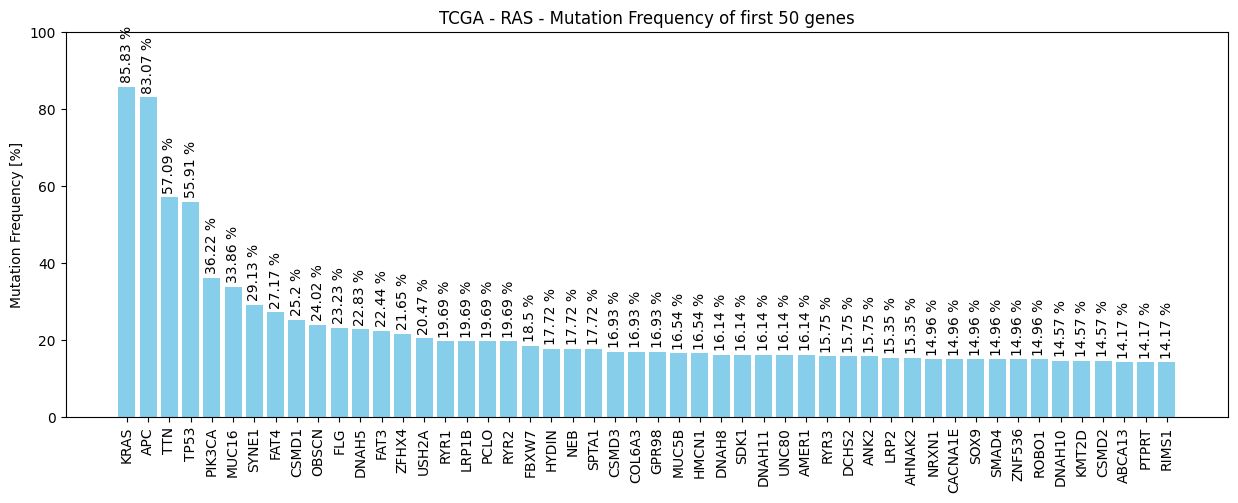

In [40]:
# plot mutation frequency of first 50 genes
plt.figure(figsize=(15, 5))
plt.bar(numPatients_perGene_RAS['Hugo_Symbol'][:50], numPatients_perGene_RAS['Mutation_Frequency[%]'][:50], color='skyblue')
plt.xticks(rotation=90)
plt.ylabel('Mutation Frequency [%]')
plt.title(dataset + ' - RAS - Mutation Frequency of first 50 genes')
# add value over each bar rotated 90 degree
for i, v in enumerate(numPatients_perGene_RAS['Mutation_Frequency[%]'][:50]):
    plt.text(i, v+1, str(round(v, 2))+ ' %', ha='center', va='bottom', rotation=90)
plt.ylim(0, 100)
plt.savefig(data[f'plots___{dataset}'] + dataset + '_mutationFrequency_first50genes_RAS.png')
plt.show()

### _CleanMemory

In [41]:
del dataMutations_RAS, dataClinicalSample_RAS, numMutatedBases_perPatient_RAS, patientsGenes_RAS, numPatients_perGene_RAS

## Non RAS-mutated samples

### Read Data

In [42]:
dataMutations_nonRAS = pd.read_csv(data[f'{dataset}_nonRAS___mutations'], sep='\t', comment='#', engine='python')
dataMutations_nonRAS

,Tumor_Sample_Barcode,Hugo_Symbol,original_Hugo_Symbol,Chromosome,Start_Position,End_Position,Strand,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele1,Tumor_Seq_Allele2,HGVSc,HGVSp_Short,Protein_position,Transcript_ID,Gene_Length,Mutation_Length,Protein_Length
0,TCGA-AF-2687-01,WDR37,WDR37,10,1130478,1130478,+,Missense_Mutation,SNP,G,G,A,ENST00000263150.4:c.532G>A,p.D178N,178.0,ENST00000263150,82760,1,494
1,TCGA-AF-2687-01,HSPA14,HSPA14,10,14896137,14896137,+,Missense_Mutation,SNP,G,G,A,ENST00000378372.3:c.748G>A,p.D250N,250.0,ENST00000378372,33578,1,509
2,TCGA-AF-2687-01,ARHGAP20,ARHGAP20,11,110450666,110450666,+,Missense_Mutation,SNP,G,G,A,ENST00000260283.4:c.3004C>T,p.P1002S,1002.0,ENST00000260283,136147,1,1191
3,TCGA-AF-2687-01,STT3A,STT3A,11,125478127,125478127,+,Missense_Mutation,SNP,G,G,A,ENST00000392708.4:c.904G>A,p.V302I,302.0,ENST00000392708,33504,1,705
4,TCGA-AF-2687-01,ANO3,ANO3,11,26620415,26620415,+,Missense_Mutation,SNP,G,G,A,ENST00000256737.3:c.1541G>A,p.R514H,514.0,ENST00000256737,474007,1,981
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
151823,TCGA-WS-AB45-01,PCDH11X,PCDH11X,X,91133412,91133412,+,Missense_Mutation,SNP,G,G,A,ENST00000373094.1:c.2173G>A,p.A725T,725.0,ENST00000373094,843970,1,1347
151824,TCGA-WS-AB45-01,TBL1X,TBL1X,X,9661224,9661224,+,Silent,SNP,C,C,T,ENST00000217964.7:c.927C>T,p.D309=,309.0,ENST00000217964,256446,1,577
151825,TCGA-WS-AB45-01,SHROOM2,SHROOM2,X,9863424,9863424,+,Silent,SNP,G,G,A,ENST00000380913.3:c.1476G>A,p.A492=,492.0,ENST00000380913,162988,1,1616
151826,TCGA-WS-AB45-01,PCDH19,PCDH19,X,99662857,99662857,+,Missense_Mutation,SNP,C,C,T,ENST00000373034.4:c.739G>A,p.V247M,247.0,ENST00000373034,118630,1,1148


In [43]:
dataClinicalSample_nonRAS = pd.read_csv(data[f'{dataset}_nonRAS___samples'], sep='\t', comment='#', engine='python')
dataClinicalSample_nonRAS

,PATIENT_ID,SAMPLE_ID,ONCOTREE_CODE,CANCER_TYPE,CANCER_TYPE_DETAILED,TUMOR_TYPE,GRADE,TISSUE_PROSPECTIVE_COLLECTION_INDICATOR,TISSUE_RETROSPECTIVE_COLLECTION_INDICATOR,TISSUE_SOURCE_SITE,TUMOR_TISSUE_SITE,ANEUPLOIDY_SCORE,SAMPLE_TYPE,MSI_SCORE_MANTIS,MSI_SENSOR_SCORE,SOMATIC_STATUS,TMB_NONSYNONYMOUS
0,TCGA-AF-2687,TCGA-AF-2687-01,READ,Colorectal Adenocarcinoma,Rectal Adenocarcinoma,Rectal Adenocarcinoma,NaN,Yes,No,AF,Rectum,24.0,Primary,0.3529,0.08,Matched,3.233333
1,TCGA-AF-2689,TCGA-AF-2689-01,READ,Colorectal Adenocarcinoma,Rectal Adenocarcinoma,Rectal Adenocarcinoma,NaN,Yes,No,AF,Rectum,18.0,Primary,0.3486,1.28,Matched,1.733333
2,TCGA-AF-2690,TCGA-AF-2690-01,READ,Colorectal Adenocarcinoma,Rectal Adenocarcinoma,Rectal Adenocarcinoma,NaN,Yes,No,AF,Rectum,25.0,Primary,0.3412,0.03,Matched,2.400000
3,TCGA-AF-2691,TCGA-AF-2691-01,READ,Colorectal Adenocarcinoma,Rectal Adenocarcinoma,Rectal Adenocarcinoma,NaN,Yes,No,AF,Rectum,11.0,Primary,0.3267,1.16,Matched,2.233333
4,TCGA-AF-2692,TCGA-AF-2692-01,READ,Colorectal Adenocarcinoma,Rectal Adenocarcinoma,Rectum Adenocarcinoma,NaN,Yes,No,AF,NaN,16.0,Primary,0.3259,1.32,Matched,0.733333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
335,TCGA-QG-A5Z1,TCGA-QG-A5Z1-01,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,Colon Adenocarcinoma,NaN,No,Yes,QG,Colon,9.0,Primary,0.2924,0.03,Matched,3.166667
336,TCGA-RU-A8FL,TCGA-RU-A8FL-01,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,Colon Adenocarcinoma,NaN,No,Yes,RU,Colon,26.0,Primary,0.3417,0.47,Matched,4.200000
337,TCGA-T9-A92H,TCGA-T9-A92H-01,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,Colon Adenocarcinoma,NaN,Yes,No,T9,Colon,11.0,Primary,0.3170,0.40,Matched,5.333333
338,TCGA-WS-AB45,TCGA-WS-AB45-01,MACR,Colorectal Adenocarcinoma,Mucinous Adenocarcinoma of the Colon and Rectum,"Colon Adenocarcinoma, Mucinous Type",NaN,No,Yes,WS,Colon,7.0,Primary,0.6782,24.48,Matched,84.166667


### Mutation Rate Analysis

In [44]:
# merge dataMutations with dataClinicalSample on Tumor_Sample_Barcode = SAMPLE_ID and extract PATIENT_ID and mutation length
numMutatedBases_perPatient_nonRAS = pd.merge(dataMutations_nonRAS, dataClinicalSample_nonRAS, left_on='Tumor_Sample_Barcode', right_on='SAMPLE_ID',  how='right')[['PATIENT_ID', 'Mutation_Length']].groupby('PATIENT_ID').sum().reset_index().rename(columns={'Mutation_Length': 'Number_Mutated_Bases'})
numMutatedBases_perPatient_nonRAS

,PATIENT_ID,Number_Mutated_Bases
0,TCGA-5M-AATA,112.0
1,TCGA-A6-2671,145.0
2,TCGA-A6-2672,0.0
3,TCGA-A6-2675,135.0
4,TCGA-A6-2676,0.0
...,...,...
335,TCGA-QG-A5YX,145.0
336,TCGA-QG-A5Z1,128.0
337,TCGA-RU-A8FL,196.0
338,TCGA-T9-A92H,217.0


In [45]:
numMutatedBases_perPatient_nonRAS['Mutation_Rate'] = numMutatedBases_perPatient_nonRAS['Number_Mutated_Bases'] / totalGeneLength
numMutatedBases_perPatient_nonRAS['Mutation_Rate[µ]'] = numMutatedBases_perPatient_nonRAS['Mutation_Rate'] * 1e6
numMutatedBases_perPatient_nonRAS = numMutatedBases_perPatient_nonRAS.sort_values(by='Mutation_Rate[µ]', ascending=False).reset_index(drop=True)
numMutatedBases_perPatient_nonRAS

,PATIENT_ID,Number_Mutated_Bases,Mutation_Rate,Mutation_Rate[µ]
0,TCGA-AG-A002,13857.0,0.000011,10.832180
1,TCGA-CA-6717,11610.0,0.000009,9.075674
2,TCGA-AA-A010,9373.0,0.000007,7.326985
3,TCGA-A6-5661,6738.0,0.000005,5.267174
4,TCGA-AA-3984,6427.0,0.000005,5.024062
...,...,...,...,...
335,TCGA-AA-A00L,0.0,0.000000,0.000000
336,TCGA-AA-A00O,0.0,0.000000,0.000000
337,TCGA-AA-A00Q,0.0,0.000000,0.000000
338,TCGA-AA-A00R,0.0,0.000000,0.000000


In [46]:
numMutatedBases_perPatient_nonRAS['hypo/hyper'] = numMutatedBases_perPatient_nonRAS.apply(lambda row: 'hyper' if row['Mutation_Rate[µ]'] > hyperThreshold else ('hypo' if row['Mutation_Rate[µ]'] < hypoThreshold else ''), axis=1)
numMutatedBases_perPatient_nonRAS

,PATIENT_ID,Number_Mutated_Bases,Mutation_Rate,Mutation_Rate[µ],hypo/hyper
0,TCGA-AG-A002,13857.0,0.000011,10.832180,hyper
1,TCGA-CA-6717,11610.0,0.000009,9.075674,hyper
2,TCGA-AA-A010,9373.0,0.000007,7.326985,hyper
3,TCGA-A6-5661,6738.0,0.000005,5.267174,hyper
4,TCGA-AA-3984,6427.0,0.000005,5.024062,hyper
...,...,...,...,...,...
335,TCGA-AA-A00L,0.0,0.000000,0.000000,hypo
336,TCGA-AA-A00O,0.0,0.000000,0.000000,hypo
337,TCGA-AA-A00Q,0.0,0.000000,0.000000,hypo
338,TCGA-AA-A00R,0.0,0.000000,0.000000,hypo


In [47]:
numHyper = numMutatedBases_perPatient_nonRAS[numMutatedBases_perPatient_nonRAS['hypo/hyper'] == 'hyper'].shape[0]
numHypo = numMutatedBases_perPatient_nonRAS[numMutatedBases_perPatient_nonRAS['hypo/hyper'] == 'hypo'].shape[0]
numPatients = numMutatedBases_perPatient_nonRAS.shape[0]
numHyper, numHypo

(15, 105)

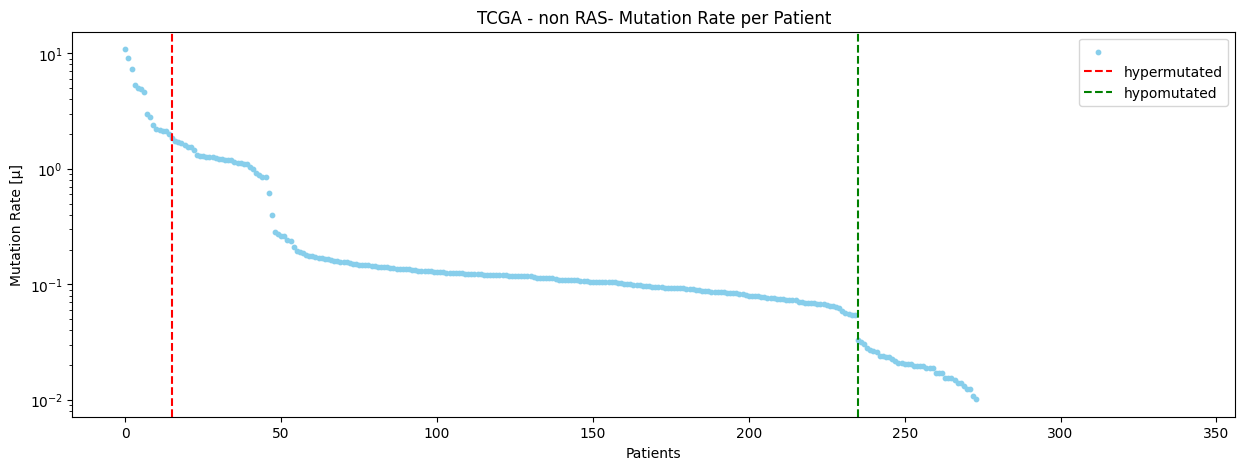

In [48]:
# plot mutation rate per patient
plt.figure(figsize=(15, 5))
plt.scatter(numMutatedBases_perPatient_nonRAS.index, numMutatedBases_perPatient_nonRAS['Mutation_Rate[µ]'], color='skyblue', s=10)
plt.yscale('log')
plt.xlabel('Patients')
plt.ylabel('Mutation Rate [µ]')
plt.title(dataset + ' - non RAS- Mutation Rate per Patient')
plt.axvline(x=numHyper, color='r', linestyle='--')
plt.axvline(x=numPatients-numHypo, color='g', linestyle='--')
plt.legend([None,'hypermutated', 'hypomutated'])
# plt.xticks([])
plt.savefig(data[f'plots___{dataset}'] + dataset + '_mutationRatePerPatient_nonRAS.png')
plt.show()

In [49]:
dataMutations_noHypoHyper_nonRAS = dataMutations_nonRAS[dataMutations_nonRAS.merge(dataClinicalSample_nonRAS, left_on='Tumor_Sample_Barcode', right_on='SAMPLE_ID')['PATIENT_ID'].isin(numMutatedBases_perPatient_nonRAS[numMutatedBases_perPatient_nonRAS['hypo/hyper'] == '']['PATIENT_ID'])]
dataMutations_noHypoHyper_nonRAS

,Tumor_Sample_Barcode,Hugo_Symbol,original_Hugo_Symbol,Chromosome,Start_Position,End_Position,Strand,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele1,Tumor_Seq_Allele2,HGVSc,HGVSp_Short,Protein_position,Transcript_ID,Gene_Length,Mutation_Length,Protein_Length
0,TCGA-AF-2687-01,WDR37,WDR37,10,1130478,1130478,+,Missense_Mutation,SNP,G,G,A,ENST00000263150.4:c.532G>A,p.D178N,178.0,ENST00000263150,82760,1,494
1,TCGA-AF-2687-01,HSPA14,HSPA14,10,14896137,14896137,+,Missense_Mutation,SNP,G,G,A,ENST00000378372.3:c.748G>A,p.D250N,250.0,ENST00000378372,33578,1,509
2,TCGA-AF-2687-01,ARHGAP20,ARHGAP20,11,110450666,110450666,+,Missense_Mutation,SNP,G,G,A,ENST00000260283.4:c.3004C>T,p.P1002S,1002.0,ENST00000260283,136147,1,1191
3,TCGA-AF-2687-01,STT3A,STT3A,11,125478127,125478127,+,Missense_Mutation,SNP,G,G,A,ENST00000392708.4:c.904G>A,p.V302I,302.0,ENST00000392708,33504,1,705
4,TCGA-AF-2687-01,ANO3,ANO3,11,26620415,26620415,+,Missense_Mutation,SNP,G,G,A,ENST00000256737.3:c.1541G>A,p.R514H,514.0,ENST00000256737,474007,1,981
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
148457,TCGA-T9-A92H-01,GPR112,GPR112,X,135428691,135428691,+,Silent,SNP,T,T,G,ENST00000370652.1:c.2826T>G,p.T942=,942.0,ENST00000370652,136094,1,3080
148458,TCGA-T9-A92H-01,DCAF8L2,DCAF8L2,X,27766401,27766401,+,Silent,SNP,T,T,C,ENST00000451261.2:c.1389T>C,p.F463=,463.0,ENST00000451261,158410,1,631
148459,TCGA-T9-A92H-01,MAGEB1,MAGEB1,X,30269452,30269452,+,Missense_Mutation,SNP,C,C,G,ENST00000378981.3:c.842C>G,p.T281S,281.0,ENST00000378981,8309,1,347
148460,TCGA-T9-A92H-01,DMD,DMD,X,32381009,32381009,+,Missense_Mutation,SNP,A,A,C,ENST00000357033.4:c.5221T>G,p.L1741V,1741.0,ENST00000357033,2241765,1,3685


In [50]:
dataMutations_noHypoHyper_nonRAS.to_csv(data[f'{dataset}_noHypoHyper_nonRAS___mutations'], sep='\t', index=False)

In [51]:
dataClinicalSample_noHypoHyper_nonRAS = dataClinicalSample_nonRAS[dataClinicalSample_nonRAS['PATIENT_ID'].isin(numMutatedBases_perPatient_nonRAS[numMutatedBases_perPatient_nonRAS['hypo/hyper'] == '']['PATIENT_ID'])]
dataClinicalSample_noHypoHyper_nonRAS

,PATIENT_ID,SAMPLE_ID,ONCOTREE_CODE,CANCER_TYPE,CANCER_TYPE_DETAILED,TUMOR_TYPE,GRADE,TISSUE_PROSPECTIVE_COLLECTION_INDICATOR,TISSUE_RETROSPECTIVE_COLLECTION_INDICATOR,TISSUE_SOURCE_SITE,TUMOR_TISSUE_SITE,ANEUPLOIDY_SCORE,SAMPLE_TYPE,MSI_SCORE_MANTIS,MSI_SENSOR_SCORE,SOMATIC_STATUS,TMB_NONSYNONYMOUS
0,TCGA-AF-2687,TCGA-AF-2687-01,READ,Colorectal Adenocarcinoma,Rectal Adenocarcinoma,Rectal Adenocarcinoma,NaN,Yes,No,AF,Rectum,24.0,Primary,0.3529,0.08,Matched,3.233333
2,TCGA-AF-2690,TCGA-AF-2690-01,READ,Colorectal Adenocarcinoma,Rectal Adenocarcinoma,Rectal Adenocarcinoma,NaN,Yes,No,AF,Rectum,25.0,Primary,0.3412,0.03,Matched,2.400000
5,TCGA-AF-2693,TCGA-AF-2693-01,READ,Colorectal Adenocarcinoma,Rectal Adenocarcinoma,Rectum Adenocarcinoma,NaN,Yes,No,AF,NaN,8.0,Primary,0.3390,0.02,Matched,2.766667
7,TCGA-AF-3911,TCGA-AF-3911-01,READ,Colorectal Adenocarcinoma,Rectal Adenocarcinoma,Rectal Adenocarcinoma,NaN,Yes,No,AF,Rectum,20.0,Primary,0.3559,0.15,Matched,2.733333
8,TCGA-AF-A56K,TCGA-AF-A56K-01,READ,Colorectal Adenocarcinoma,Rectal Adenocarcinoma,Rectal Adenocarcinoma,NaN,No,Yes,AF,Rectum,14.0,Primary,0.3197,0.29,Matched,2.933333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
334,TCGA-QG-A5YX,TCGA-QG-A5YX-01,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,Colon Adenocarcinoma,NaN,No,Yes,QG,Colon,10.0,Primary,0.3040,0.18,Matched,2.700000
335,TCGA-QG-A5Z1,TCGA-QG-A5Z1-01,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,Colon Adenocarcinoma,NaN,No,Yes,QG,Colon,9.0,Primary,0.2924,0.03,Matched,3.166667
336,TCGA-RU-A8FL,TCGA-RU-A8FL-01,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,Colon Adenocarcinoma,NaN,No,Yes,RU,Colon,26.0,Primary,0.3417,0.47,Matched,4.200000
337,TCGA-T9-A92H,TCGA-T9-A92H-01,COAD,Colorectal Adenocarcinoma,Colon Adenocarcinoma,Colon Adenocarcinoma,NaN,Yes,No,T9,Colon,11.0,Primary,0.3170,0.40,Matched,5.333333


In [52]:
dataClinicalSample_noHypoHyper_nonRAS.to_csv(data[f'{dataset}_noHypoHyper_nonRAS___samples'], sep='\t', index=False)

### Mutation Frequency Analysis

In [53]:
patientsGenes_nonRAS = pd.merge(dataMutations_nonRAS, dataClinicalSample_nonRAS, left_on='Tumor_Sample_Barcode', right_on='SAMPLE_ID')[['PATIENT_ID', 'Hugo_Symbol']].drop_duplicates().reset_index(drop=True)
patientsGenes_nonRAS

,PATIENT_ID,Hugo_Symbol
0,TCGA-AF-2687,WDR37
1,TCGA-AF-2687,HSPA14
2,TCGA-AF-2687,ARHGAP20
3,TCGA-AF-2687,STT3A
4,TCGA-AF-2687,ANO3
...,...,...
124606,TCGA-WS-AB45,PCDH11X
124607,TCGA-WS-AB45,TBL1X
124608,TCGA-WS-AB45,SHROOM2
124609,TCGA-WS-AB45,PCDH19


In [54]:
numPatients_perGene_nonRAS = patientsGenes_nonRAS.groupby('Hugo_Symbol').count().reset_index().rename(columns={'PATIENT_ID': 'Number_Patients'})
numPatients_perGene_nonRAS

,Hugo_Symbol,Number_Patients
0,A1BG,8
1,A1CF,6
2,A2M,25
3,A2ML1,24
4,A3GALT2,6
...,...,...
17995,ZYG11B,9
17996,ZYX,6
17997,ZZEF1,27
17998,ZZZ3,13


In [55]:
numPatients_nonRAS = dataClinicalSample_nonRAS['PATIENT_ID'].nunique()
numPatients_nonRAS

340

In [56]:
numPatients_perGene_nonRAS['Mutation_Frequency[%]'] = numPatients_perGene_nonRAS['Number_Patients'] / numPatients_nonRAS * 100
numPatients_perGene_nonRAS = numPatients_perGene_nonRAS.sort_values(by='Mutation_Frequency[%]', ascending=False).reset_index(drop=True)
numPatients_perGene_nonRAS

,Hugo_Symbol,Number_Patients,Mutation_Frequency[%]
0,APC,173,50.882353
1,TP53,161,47.352941
2,TTN,143,42.058824
3,SYNE1,90,26.470588
4,MUC16,85,25.000000
...,...,...,...
17995,RPL13,1,0.294118
17996,RPL22L1,1,0.294118
17997,RPL23,1,0.294118
17998,RPL26,1,0.294118


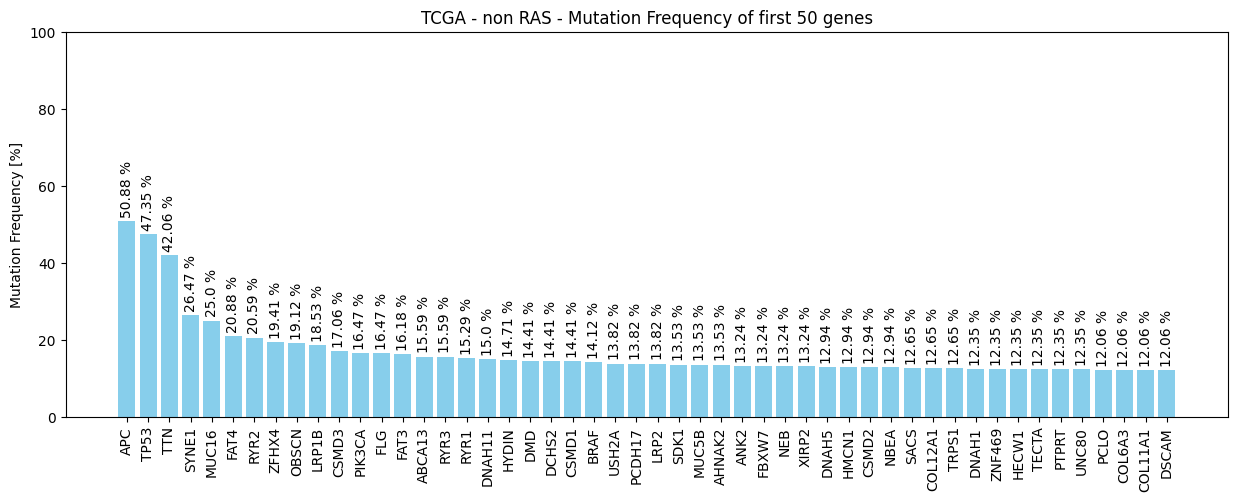

In [57]:
# plot mutation frequency of first 50 genes
plt.figure(figsize=(15, 5))
plt.bar(numPatients_perGene_nonRAS['Hugo_Symbol'][:50], numPatients_perGene_nonRAS['Mutation_Frequency[%]'][:50], color='skyblue')
plt.xticks(rotation=90)
plt.ylabel('Mutation Frequency [%]')
plt.title(dataset + ' - non RAS - Mutation Frequency of first 50 genes')
# add value over each bar rotated 90 degree
for i, v in enumerate(numPatients_perGene_nonRAS['Mutation_Frequency[%]'][:50]):
    plt.text(i, v+1, str(round(v, 2))+ ' %', ha='center', va='bottom', rotation=90)
plt.ylim(0, 100)
plt.savefig(data[f'plots___{dataset}'] + dataset + '_mutationFrequency_first50genes_nonRAS.png')
plt.show()

### _CleanMemory

In [58]:
del dataMutations_nonRAS, dataClinicalSample_nonRAS, numMutatedBases_perPatient_nonRAS, patientsGenes_nonRAS, numPatients_perGene_nonRAS